# SETUP

In [ ]:
import os
import sklearn
import joblib
from google.colab import drive

# Hubungkan ke Google Drive
drive.mount

# Folder Penyimpanan Artefa Model
ARTIFACT_DIR ="/content/drive/MyDrive/Learn Data Scientis/AI-Projects/fraud-anomaly-detection/artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)


print(f"Folder artefak siap: {ARTIFACT_DIR}")
print(f"Versi scikit-learn: {sklearn.__version__} | joblib: {joblib.__version__}")

Folder artefak siap: /content/drive/MyDrive/Learn Data Scientis/AI-Projects/fraud-anomaly-detection/artifacts
Versi scikit-learn: 1.6.1 | joblib: 1.6.0


# Mengambil Dataset dari Kaggle

In [ ]:
from kagglehub.models import DEFAULT_IGNORE_PATTERNS
import kagglehub
import pandas as pd
from sklearn.model_selection import train_test_split

# Unduh dataset langsung dari Kaggle
path = kagglehub.dataset_download("ealaxi/paysim1")
csv_file = [ f for f in os.listdir(path) if f.endswith(".csv")][0]
df_raw = pd.read_csv(os.path.join(path, csv_file))
print(f"Total baris dataset asli : {df_raw.shape[0],}")

# Ambil sampel 200.00 baris dengan proporsi isfraud tetap terjaga
df,_ = train_test_split(
    df_raw,
    test_size=200000,
    stratify=df_raw["isFraud"],
    random_state=42
)

print(f"Ukuran sampel kerja: {df.shape[0]}")
df.head()

Using Colab cache for faster access to the 'paysim1' dataset.
Total baris dataset asli : (6362620,)
Ukuran sampel kerja: 6162620


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
3095582,235,CASH_IN,352644.12,C956260300,94343.00,446987.12,C2075502161,1573207.02,1855903.80,0,0
2161041,184,PAYMENT,14940.81,C399031315,62050.22,47109.41,M344487942,0.00,0.00,0,0
3028931,233,PAYMENT,4498.53,C1101651605,0.00,0.00,M1395431783,0.00,0.00,0,0
1461814,140,CASH_OUT,87508.70,C232874732,0.00,0.00,C1747986197,626974.72,714483.42,0,0
1176754,132,PAYMENT,3389.39,C1607051670,133745.46,130356.07,M168924447,0.00,0.00,0,0


# Audit Kualitas Data & Eksplorasi Singkat (EDA)

Total missing values 0
Total baris duplikat 0

Proporsi Kelas Fraud:
isFraud
0    99.8709
1     0.1291
Name: proportion, dtype: float64

Jumlah Fraud per Jenis Transaksi:
isFraud         0     1
type                   
CASH_IN   1355433     0
CASH_OUT  2163127  3994
DEBIT       40110     0
PAYMENT   2083864     0
TRANSFER   512131  3961


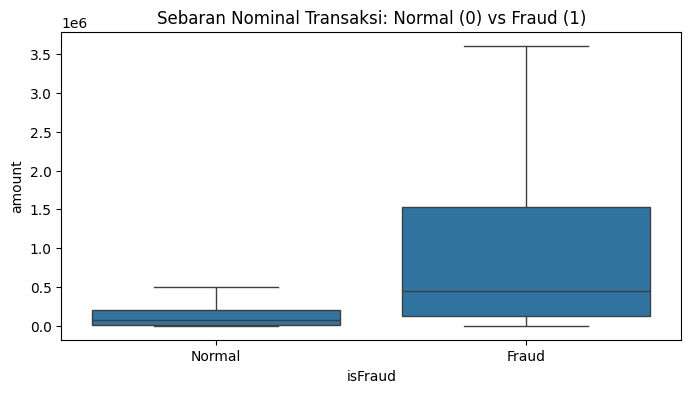

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Cek missing values & duplikasi
print("Total missing values", df.isnull().sum().sum())
print("Total baris duplikat", df.duplicated().sum())

# 2. Cek Proporsi Kelas ( 0 = Normal, 1 = Fraud)
print("\nProporsi Kelas Fraud:")
print((df["isFraud"].value_counts(normalize=True) * 100).round(4))

# 3. Cek jenis Transaksi yang mengandung kasus Fraud
print("\nJumlah Fraud per Jenis Transaksi:")
print(pd.crosstab(df['type'], df['isFraud']))

# 4. Visualisasi sebaran nominal transaksi (amount)
plt.figure(figsize=(8, 4))
sns.boxplot(x='isFraud', y='amount', data=df, showfliers=False)
plt.title("Sebaran Nominal Transaksi: Normal (0) vs Fraud (1)")
plt.xticks([0, 1], ["Normal", "Fraud"])
plt.show()



# Seleksi Fitur & Pembagian Data Latih-Uji

In [ ]:
num_feautures = [
    'step', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest'
]

cat_features = ['type']
target = 'isFraud'

X = df[num_feautures + cat_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Data Latih: {X_train.shape[0]:,} baris | Data Uji: {X_test.shape[0]:,} baris")

Data Latih: 4,930,096 baris | Data Uji: 1,232,524 baris


# Pipeline Prapemrosesan & Model Isolation Forest

In [ ]:
from numpy import random
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.ensemble import IsolationForest

# Pipeline untuk Fitur Numerik
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# Pipeline untuk Fitur Kategorikal
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Gabungkan Preprocessor menggunakan ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_feautures),
        ('cat', categorical_transformer, cat_features)
    ]
)

# Gabungkan Preprocessor dan model deteksi anomali
anomaly_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('detector', IsolationForest(
        n_estimators=200,
        contamination=0.0015,
        random_state=42,
        n_jobs=-1
    ))
])

# Latih Pipeline (Unsupervised: Tanpa Melihat label y_train)
anomaly_pipeline.fit(X_train)
print("Pelatihan Selesai !!")

Pelatihan Selesai !!


# Evaluasi Performa dengan PR-AUC & Kurva Precision Recall

PR-AUC Score pada Data Uji: 0.0071

Laporan Klasifikasi (Ambang Batas Top 1%):
              precision    recall  f1-score   support

           0     0.9988    0.9901    0.9944   1230933
           1     0.0092    0.0717    0.0164      1591

    accuracy                         0.9889   1232524
   macro avg     0.5040    0.5309    0.5054   1232524
weighted avg     0.9975    0.9889    0.9932   1232524



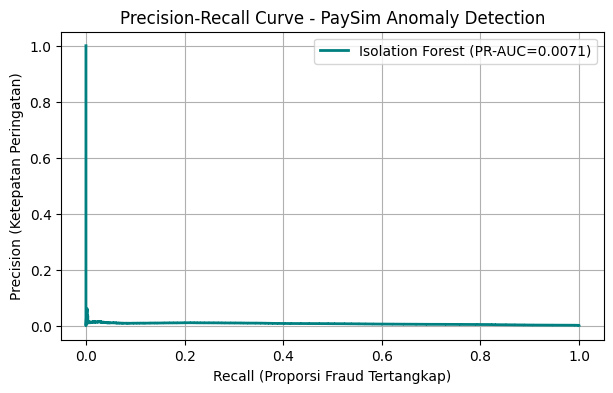

In [ ]:
import numpy as np
from sklearn.metrics import average_precision_score, precision_recall_curve, classification_report

# Balik tanda decision_function agar skor makin tinggi = makin anomali
anomaly_scores = -anomaly_pipeline.decision_function(X_test)

# 1. Hitung Skor PR-AUC
pr_auc = average_precision_score(y_test, anomaly_scores)
print(f"PR-AUC Score pada Data Uji: {pr_auc:.4f}")

# 2. Evaluasi jika mengambil ambang batas Top 1% Skor tertinggi
threshold_top1 = np.percentile(anomaly_scores, 99)
y_pred_top1 = (anomaly_scores >= threshold_top1).astype(int)

print("\nLaporan Klasifikasi (Ambang Batas Top 1%):")
print(classification_report(y_test, y_pred_top1, digits=4))

# 3. Plot Curva Precision-Recall
precision, recall, _ = precision_recall_curve(y_test, anomaly_scores)
plt.figure(figsize=(7, 4))
plt.plot(recall, precision, color='teal', lw=2, label=f'Isolation Forest (PR-AUC={pr_auc:.4f})')
plt.xlabel('Recall (Proporsi Fraud Tertangkap)')
plt.ylabel('Precision (Ketepatan Peringatan)')
plt.title('Precision-Recall Curve - PaySim Anomaly Detection')
plt.legend()
plt.grid(True)
plt.show()

# Interprestasi Fitur Pemicu Anomali dengan SHAP

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


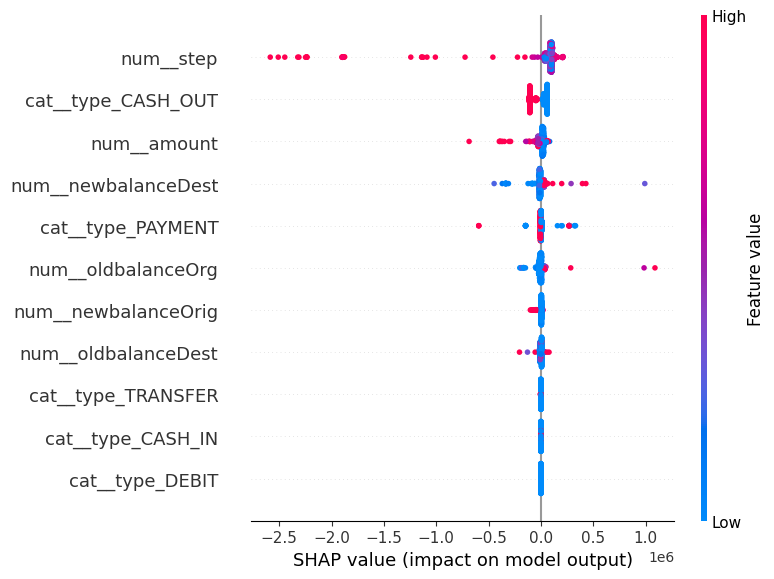

In [ ]:
import shap
import lightgbm as lgb
import pandas as pd

# Ambil nama Fitur setelah melewati One Hot Encoder
features_names = anomaly_pipeline.named_steps['preprocessor'].get_feature_names_out()

X_train_trans = anomaly_pipeline.named_steps['preprocessor'].transform(X_train)
X_test_trans = pd.DataFrame(
    anomaly_pipeline.named_steps['preprocessor'].transform(X_test),
    columns=features_names
)

# Definisikan model surrogate menggunakan LGBMClassifier
surrogate = lgb.LGBMClassifier(n_estimators=100, random_state=42, verbose=-1)

# Latih model surrogate menggunakan label biner hasil prediksi Isolation Forest pada data latih
# (predict menghasilkan -1 untuk anomali, 1 untuk normal; kita ubah anomali menjadi 1 dan normal menjadi 0)
y_train_pred = anomaly_pipeline.named_steps['detector'].predict(X_train_trans)
y_train_iso = (y_train_pred == -1).astype(int)

surrogate.fit(X_train_trans, y_train_iso)

# Hitung SHAP values pada 500 sampel data uji
explainer = shap.TreeExplainer(surrogate)
shap_values = explainer.shap_values(X_test_trans.iloc[:500])
if isinstance(shap_values, list):
  shap_values = shap_values[1]

shap.summary_plot(shap_values, X_test_trans.iloc[:500])

# Simpan Arterfak Model & Metadata ke Google Drive

In [ ]:
import json

# 1. Simpan pipeline utuh
model_path = os.path.join(ARTIFACT_DIR, "fraud_anomaly_pipeline.joblib")
joblib.dump(anomaly_pipeline, model_path)

# 2. Simpan metadata skema, versi library, dan threshold risiko
metadata = {
    "model_name": "paysim_isolation_forest_v1",
    "sklearn_version": sklearn.__version__,
    "joblib_version": joblib.__version__,
    "num_features": num_feautures, # Memperbaiki typo dari num_features menjadi num_feautures
    "cat_features": cat_features,
    "thresholds": {
        "high_risk": round(float(np.percentile(anomaly_scores, 99.5)), 6),
        "medium_risk": round(float(np.percentile(anomaly_scores, 98.0)), 6)
    },
    "metrics": {
        "pr_auc_test": round(float(pr_auc), 4)
    }
}

meta_path = os.path.join(ARTIFACT_DIR, "model_metadata.json")
with open(meta_path, "w") as f:
    json.dump(metadata, f, indent=2)

print("Artefak berhasil disimpan ke Google Drive:")
print("-", model_path)
print("-", meta_path)

Artefak berhasil disimpan ke Google Drive:
- /content/drive/MyDrive/Learn Data Scientis/AI-Projects/fraud-anomaly-detection/artifacts/fraud_anomaly_pipeline.joblib
- /content/drive/MyDrive/Learn Data Scientis/AI-Projects/fraud-anomaly-detection/artifacts/model_metadata.json


# Domain Feature Engineering & Model Benchmarking

In [ ]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score, classification_report

# 1. Filter hanya tipe transaksi yang relevan (berdasarkan temuan EDA Sel 3)
df_filtered = df[df['type'].isin(['TRANSFER', 'CASH_OUT'])].copy()

# 2. Fungsi Feature Engineering murni (mudah dipakai ulang di FastAPI nanti)
def add_domain_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()
    # Jam dalam sehari (0-23) menggantikan step mentah
    d['hour_of_day'] = d['step'] % 24

    # Selisih akuntansi saldo pengirim & penerima
    d['errorBalanceOrig'] = d['newbalanceOrig'] + d['amount'] - d['oldbalanceOrg']
    d['errorBalanceDest'] = d['oldbalanceDest'] + d['amount'] - d['newbalanceDest']

    # Indikator biner: rekening pengirim dikuras habis menjadi 0
    d['is_orig_drained'] = ((d['oldbalanceOrg'] > 0) & (d['newbalanceOrig'] == 0)).astype(int)

    # Indikator biner: uang dikirim (> 0) tetapi saldo penerima tetap 0
    d['is_dest_unchanged'] = (
        (d['amount'] > 0) & (d['oldbalanceDest'] == 0) & (d['newbalanceDest'] == 0)
    ).astype(int)
    return d

df_feat = add_domain_features(df_filtered)

# 3. Tentukan daftar fitur baru
num_features = [
    'hour_of_day', 'amount',
    'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest',
    'errorBalanceOrig', 'errorBalanceDest',
    'is_orig_drained', 'is_dest_unchanged'
]
cat_features = ['type']

X = df_feat[num_features + cat_features]
y = df_feat['isFraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 4. Bangun Preprocessor Standar
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', RobustScaler())
        ]), num_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), cat_features)
    ]
)

# 5A. Model 1: Unsupervised Isolation Forest (dengan fitur baru)
iso_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('detector', IsolationForest(
        n_estimators=300,
        contamination=float(y_train.mean()),
        random_state=42,
        n_jobs=-1
    ))
])
iso_pipeline.fit(X_train)
iso_scores = -iso_pipeline.decision_function(X_test)
pr_auc_iso = average_precision_score(y_test, iso_scores)

# 5B. Model 2: Supervised LightGBM (sebagai benchmark performa maksimal)
lgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', lgb.LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        class_weight='balanced',
        random_state=42,
        verbose=-1
    ))
])
lgb_pipeline.fit(X_train, y_train)
lgb_probs = lgb_pipeline.predict_proba(X_test)[:, 1]
pr_auc_lgb = average_precision_score(y_test, lgb_probs)

print(f"PR-AUC Sebelumnya (Fitur Mentah)        : 0.0071")
print(f"PR-AUC Isolation Forest (Fitur Baru)    : {pr_auc_iso:.4f}")
print(f"PR-AUC LightGBM Benchmark (Fitur Baru)  : {pr_auc_lgb:.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


PR-AUC Sebelumnya (Fitur Mentah)        : 0.0071
PR-AUC Isolation Forest (Fitur Baru)    : 0.0540
PR-AUC LightGBM Benchmark (Fitur Baru)  : 0.9978


# Ekspor Artefak Hybrid Model & Uji Simulasi Payload API

In [ ]:
import json
import joblib
import sklearn
import lightgbm as lgb
import numpy as np
import pandas as pd

# 1. Simpan kedua pipeline (Supervised LightGBM + Unsupervised Isolation Forest)
lgb_path = os.path.join(ARTIFACT_DIR, "fraud_lgb_pipeline.joblib")
iso_path = os.path.join(ARTIFACT_DIR, "fraud_iso_pipeline.joblib")

joblib.dump(lgb_pipeline, lgb_path)
joblib.dump(iso_pipeline, iso_path)

# 2. Simpan metadata lengkap (versi library, fitur mentah, fitur turunan, & threshold)
raw_required_fields = [
    "step", "type", "amount",
    "oldbalanceOrg", "newbalanceOrig",
    "oldbalanceDest", "newbalanceDest"
]

metadata = {
    "model_version": "paysim_hybrid_v2",
    "environment": {
        "sklearn_version": sklearn.__version__,
        "lightgbm_version": lgb.__version__,
        "joblib_version": joblib.__version__
    },
    "raw_input_fields": raw_required_fields,
    "engineered_num_features": num_features,
    "cat_features": cat_features,
    "allowed_transaction_types": ["TRANSFER", "CASH_OUT"],
    "thresholds": {
        "lgb_high_risk_prob": 0.80,
        "lgb_medium_risk_prob": 0.40,
        "iso_anomaly_cutoff": round(float(np.percentile(iso_scores, 98.0)), 6)
    },
    "metrics": {
        "pr_auc_lightgbm": round(float(pr_auc_lgb), 4),
        "pr_auc_isolation_forest": round(float(pr_auc_iso), 4)
    }
}

meta_path = os.path.join(ARTIFACT_DIR, "model_metadata.json")
with open(meta_path, "w") as f:
    json.dump(metadata, f, indent=2)

print("Semua artefak v2 berhasil disimpan ke Google Drive!")
print(f"- LightGBM Pipeline : {lgb_path}")
print(f"- IsoForest Pipeline: {iso_path}")
print(f"- Metadata JSON     : {meta_path}")

# 3. Simulasi End-to-End Inference (1 Payload JSON Mentah -> Feature Eng -> Prediksi Hybrid)
sample_payload = {
    "step": 215,
    "type": "TRANSFER",
    "amount": 450000.0,
    "oldbalanceOrg": 450000.0,
    "newbalanceOrig": 450000.0,  # Saldo tidak berkurang meski transfer besar (pola fraud)
    "oldbalanceDest": 0.0,
    "newbalanceDest": 0.0
}

# Jalankan alur persis seperti yang akan dijalankan FastAPI nanti
df_input = pd.DataFrame([sample_payload])
df_engineered = add_domain_features(df_input)

loaded_lgb = joblib.load(lgb_path)
loaded_iso = joblib.load(iso_path)

fraud_prob = float(loaded_lgb.predict_proba(df_engineered)[0, 1])
anomaly_score = float(-loaded_iso.decision_function(df_engineered)[0])

print("\n--- Hasil Simulasi Inferensi API ---")
print(f"Probabilitas Fraud (LightGBM)      : {fraud_prob:.4f}")
print(f"Skor Anomali (Isolation Forest)    : {anomaly_score:.4f} (Cutoff: {metadata['thresholds']['iso_anomaly_cutoff']})")

Semua artefak v2 berhasil disimpan ke Google Drive!
- LightGBM Pipeline : /content/drive/MyDrive/Learn Data Scientis/AI-Projects/fraud-anomaly-detection/artifacts/fraud_lgb_pipeline.joblib
- IsoForest Pipeline: /content/drive/MyDrive/Learn Data Scientis/AI-Projects/fraud-anomaly-detection/artifacts/fraud_iso_pipeline.joblib
- Metadata JSON     : /content/drive/MyDrive/Learn Data Scientis/AI-Projects/fraud-anomaly-detection/artifacts/model_metadata.json

--- Hasil Simulasi Inferensi API ---
Probabilitas Fraud (LightGBM)      : 0.9976
Skor Anomali (Isolation Forest)    : -0.0198 (Cutoff: -0.101297)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
